#Exploratory Data Analysis





What is Exploratory Data Analysis? Why is it important?

It is the base and foundational process of any type of data analysing or visualisation task, as it helps us understand the data structure, features, recognise any anomolies(outliers) and importantly check the relationships between variables before bulding our models.

This generally takes up to **75%** of the total job of bulding ML projects and is deeply important to aovid any future biases or any other issues that may arise with your model in the future.

Now that we understand what EDA is, What does the typical workflow look like?

The general step by step process of EDA looks something like this:

*  Understanding the dataset and its variables.
*  Inspecting data using Pandas.
* Handling Outtliers
* Handling the Missiing Data
* Scaling Our Data
* Transforming OUr Data
* Bulding And Evaluating our Model



If you want read about this in further detail use this [Exploratory Data Analysis](https://www.geeksforgeeks.org/data-analysis/what-is-exploratory-data-analysis/)







Commonly Pyhton or R programming is used to perform such tasks but we will mainly focusing on using pyhton and its libraries to explore our data as it is better for deploying machine learning and more versatile whereas R is better in terms of more statistical analysis and data visualisations.


More infromation on the pros and cons of [Pyhton vs R](https://lset.uk/blog/r-vs-python-a-comparative-analysis-for-data-science/).


#Understanding the Problem and the Data

The first step to any ML task/project is to understand the problem and figuring out if the data that we have is what we need to solve the porblem and whether it aligns with our goals of creating the model in the first place.

It will help us understand what are the features(columns/attributes) that are going to be relevant and which are reduntant to our models.

What are some common question to ask yourself when you are exploring your data?


*   What is the goal or problem we are trying to solve?
*   What variables are present in the dataset and what do they represent?
*   What types of data are available (numerical, categorical, text etc.)?
*   Are there any data quality issues or limitations?

These are just some of the basic and kind of generic quetions you may ask yourself, it will be different depending upon the ML project or the context of the data collected which is what makes it an essential step when it comes to Exploratroy Data analysis.



Our objective is to investigate the factors associated with smartphone addiction and use the available information to predict whether an individual is classified as addicted or not addicted.

Now Let us come to the main bulk of the job, that is the pre-processing of our data (which is what step 2-7 is going to be). Here we will be doing the main tasks of cleaning, visualising, transforming our data and getting it ready for our model to train.

#Importing and Inspecting the Data

Here we will load our dataset(s) into our notebook and inspect our data for any missing or dulpicate datapoints, check the overall shape of our data, the number of rows and columns, etc

In [ ]:
# Install external packages
!pip install -q pyampute

In [ ]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats


In [68]:
#delete this later
#Firstly we will import our data using pandas library
import pandas as pd
#Then we will use pd.read_csv to read our csv file into our python environment
filepath = 'https://raw.githubusercontent.com/sheffdatasoc/2026-27/refs/heads/main/Exploratory%20Analysis%20180%20week/Smartphone_Addiction.csv'
df = pd.read_csv(filepath)

In [ ]:
#df.to_csv("Smartphone_Addiction",index=False)

In [ ]:
# To check the shape of our data i.e. the number of rows and columns
df.shape

(1000, 13)


| Column Name | Description |
|---|---|
| `age` | User age (18–35) |
| `gender` | Male / Female / Other |
| `daily_screen_time_hours` | Total daily screen time |
| `social_media_hours` | Daily time spent on social media |
| `gaming_hours` | Daily time spent gaming |
| `work_study_hours` | Daily time spent on work/study |
| `sleep_hours` | Daily sleep duration |
| `notifications_per_day` | Number of daily notifications |
| `app_opens_per_day` | Number of times apps are opened per day |
| `weekend_screen_time` | Screen time on weekends |
| `stress_level` | Low / Medium / High |
| `academic_work_impact` | Whether phone usage impacts work/study (Yes/No) |
| `addicted_label` | Binary label: 1 = Addicted, 0 = Not Addicted |


In [ ]:
# To check the statistics insights on all our columns
df.describe()

,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,addicted_label
count,952.000000,876.000000,804.000000,839.000000,929.000000,951.000000,904.000000,885.000000,835.000000,1000.00000
mean,26.766807,7.508299,2.435846,1.420155,2.388181,6.759201,142.063053,105.343503,9.382443,0.70800
std,5.139917,2.813167,1.351847,0.920430,1.296281,1.224770,65.236612,47.483714,2.875428,0.45491
min,18.000000,0.960000,0.080000,0.010000,0.200000,4.500000,20.000000,16.000000,2.130000,0.00000
25%,22.000000,5.290000,1.397500,0.680000,1.350000,5.720000,92.000000,68.000000,7.230000,0.00000
50%,27.000000,7.645000,2.280000,1.310000,2.210000,6.760000,142.000000,109.000000,9.500000,1.00000
75%,31.000000,9.820000,3.350000,1.995000,3.210000,7.830000,197.000000,146.000000,11.745000,1.00000
max,35.000000,13.430000,6.320000,4.000000,5.940000,8.980000,249.000000,180.000000,17.150000,1.00000


In [ ]:
# This returns the number of non-null values and data types of each column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      952 non-null    float64
 1   daily_screen_time_hours  876 non-null    float64
 2   social_media_hours       804 non-null    float64
 3   gaming_hours             839 non-null    float64
 4   work_study_hours         929 non-null    float64
 5   sleep_hours              951 non-null    float64
 6   notifications_per_day    904 non-null    float64
 7   app_opens_per_day        885 non-null    float64
 8   weekend_screen_time      835 non-null    float64
 9   gender                   957 non-null    object 
 10  stress_level             921 non-null    object 
 11  academic_work_impact     939 non-null    object 
 12  addicted_label           1000 non-null   float64
dtypes: float64(10), object(3)
memory usage: 101.7+ KB


In [ ]:
# To check eihter first 5 rows of data or last 5 rows of data if you use tail()
df.head()

,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
0,33.0,7.91,1.89,1.96,3.19,4.75,112.0,179.0,10.25,Other,Medium,No,1.0
1,29.0,12.47,1.24,0.13,4.12,5.94,40.0,85.0,10.23,Male,Medium,Yes,1.0
2,29.0,12.75,3.77,2.48,5.60,6.81,202.0,49.0,13.18,Female,Low,Yes,1.0
3,32.0,8.96,2.76,2.62,3.02,7.99,226.0,109.0,10.05,Other,High,No,1.0
4,33.0,8.43,3.46,2.58,1.63,6.49,84.0,140.0,8.69,Other,Low,No,1.0


In [ ]:
#df.drop(columns = ['Unnamed: 0'],inplace=True)

In [ ]:
# To return a list of the columns in the dataset
df.columns

Index(['age', 'daily_screen_time_hours', 'social_media_hours', 'gaming_hours',
       'work_study_hours', 'sleep_hours', 'notifications_per_day',
       'app_opens_per_day', 'weekend_screen_time', 'gender', 'stress_level',
       'academic_work_impact', 'addicted_label'],
      dtype='object')

In [ ]:
# To check the data types of each column
df.dtypes

,0
age,float64
daily_screen_time_hours,float64
social_media_hours,float64
gaming_hours,float64
work_study_hours,float64
sleep_hours,float64
notifications_per_day,float64
app_opens_per_day,float64
weekend_screen_time,float64
gender,object


####Some more optional functions you may use depending on the data you are working with.

In [ ]:
# OR if you want to select a subset of columns with a certain datatype
#df.select_dtypes(include='',exclude='')

df.select_dtypes(include='object',exclude='float64')


In [ ]:
# To check for any duplicate values
#df.duplicated(subset=['List_of_columns'],keep=true/False)
# is also useful to see if there are any rows in total are being duplicated
df.duplicated().sum()

np.int64(0)

# Exploring Data Characteristics

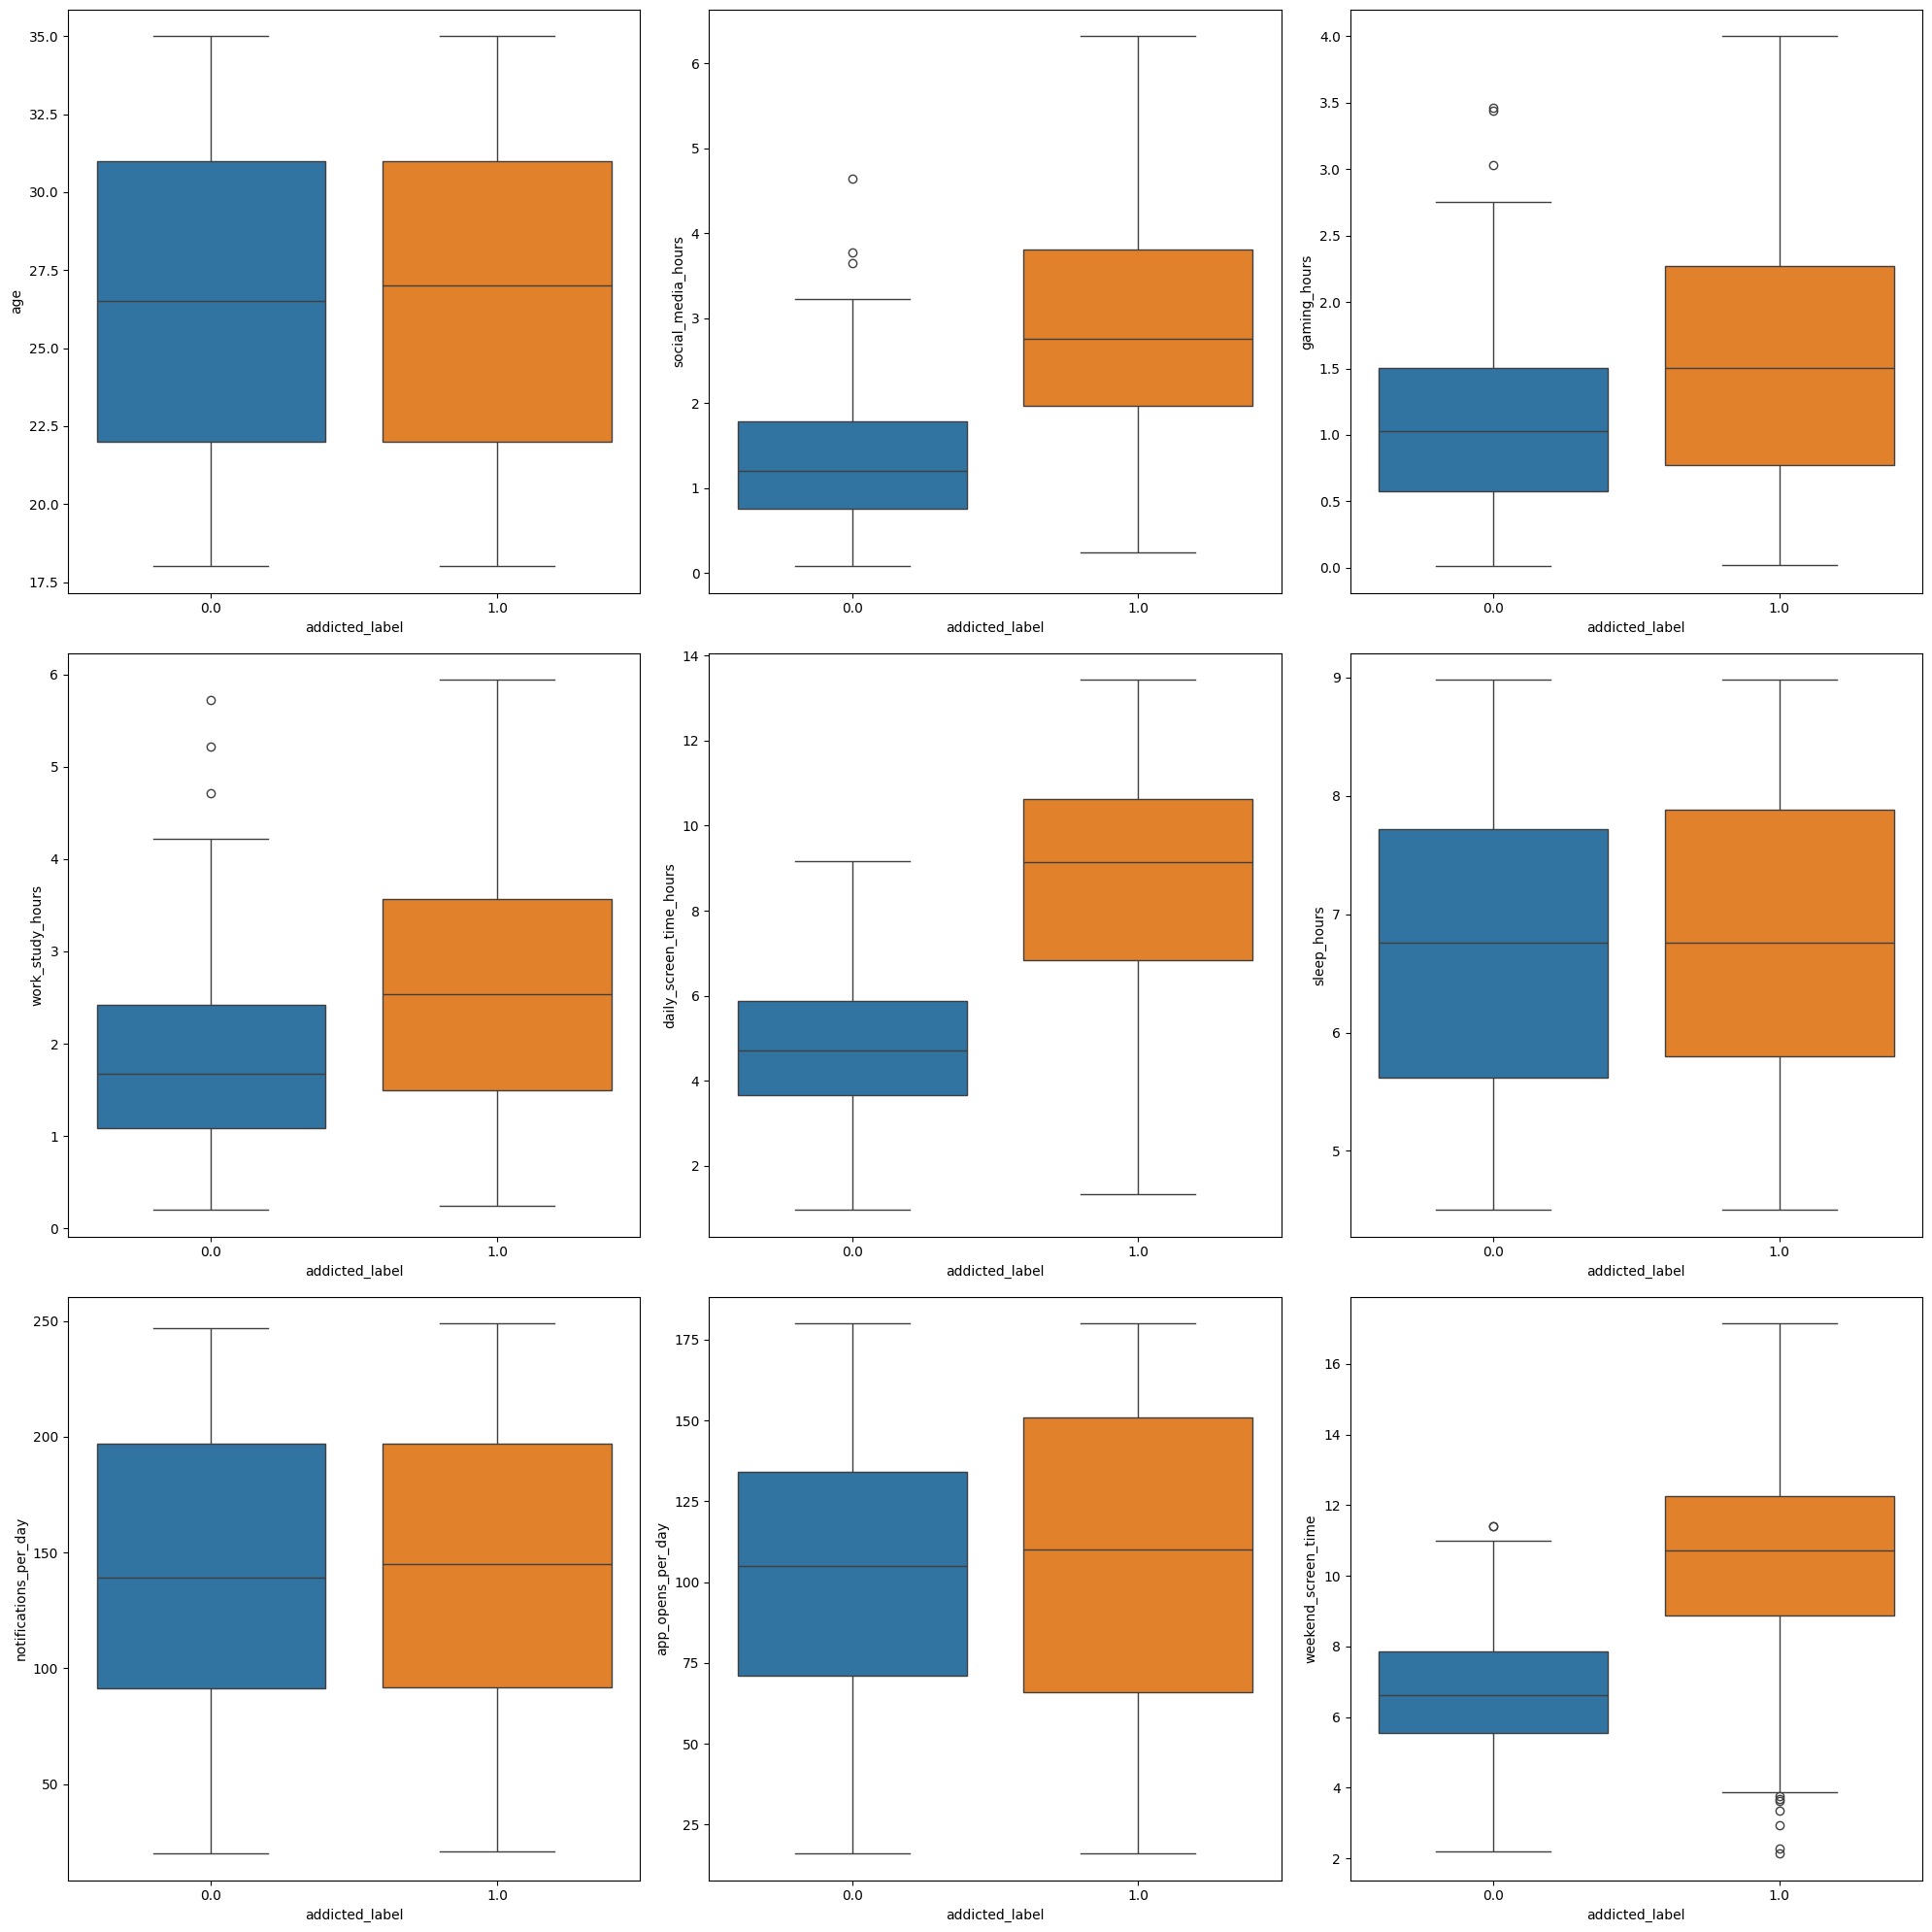

In [ ]:

fig, axes = plt.subplots(3, 3, figsize=(20, 20))

sns.boxplot(ax=axes[0][0], data=df, x='addicted_label', y='age', hue="addicted_label", legend=False) # age
sns.boxplot(ax=axes[0][1], data=df, x='addicted_label', y='social_media_hours', hue="addicted_label", legend=False) # social_media_hours
sns.boxplot(ax=axes[0][2], data=df, x='addicted_label', y='gaming_hours', hue="addicted_label", legend=False) # gaming_hours
sns.boxplot(ax=axes[1][0], data=df, x='addicted_label', y='work_study_hours', hue="addicted_label", legend=False) # work_study_hours
sns.boxplot(ax=axes[1][1], data=df, x='addicted_label', y='daily_screen_time_hours', hue="addicted_label", legend=False) # daily_screen_time_hours
sns.boxplot(ax=axes[1][2], data=df, x='addicted_label', y='sleep_hours', hue="addicted_label", legend=False) # sleep_hours
sns.boxplot(ax=axes[2][0], data=df, x='addicted_label', y='notifications_per_day', hue="addicted_label", legend=False) # notifications_per_day
sns.boxplot(ax=axes[2][1], data=df, x='addicted_label', y='app_opens_per_day', hue="addicted_label", legend=False) # app_opens_per_day
sns.boxplot(ax=axes[2][2], data=df, x='addicted_label', y='weekend_screen_time', hue="addicted_label", legend=False) # weekend_screen_time



plt.tight_layout()
plt.show()

In [ ]:
df_new=df.copy() #making a copy

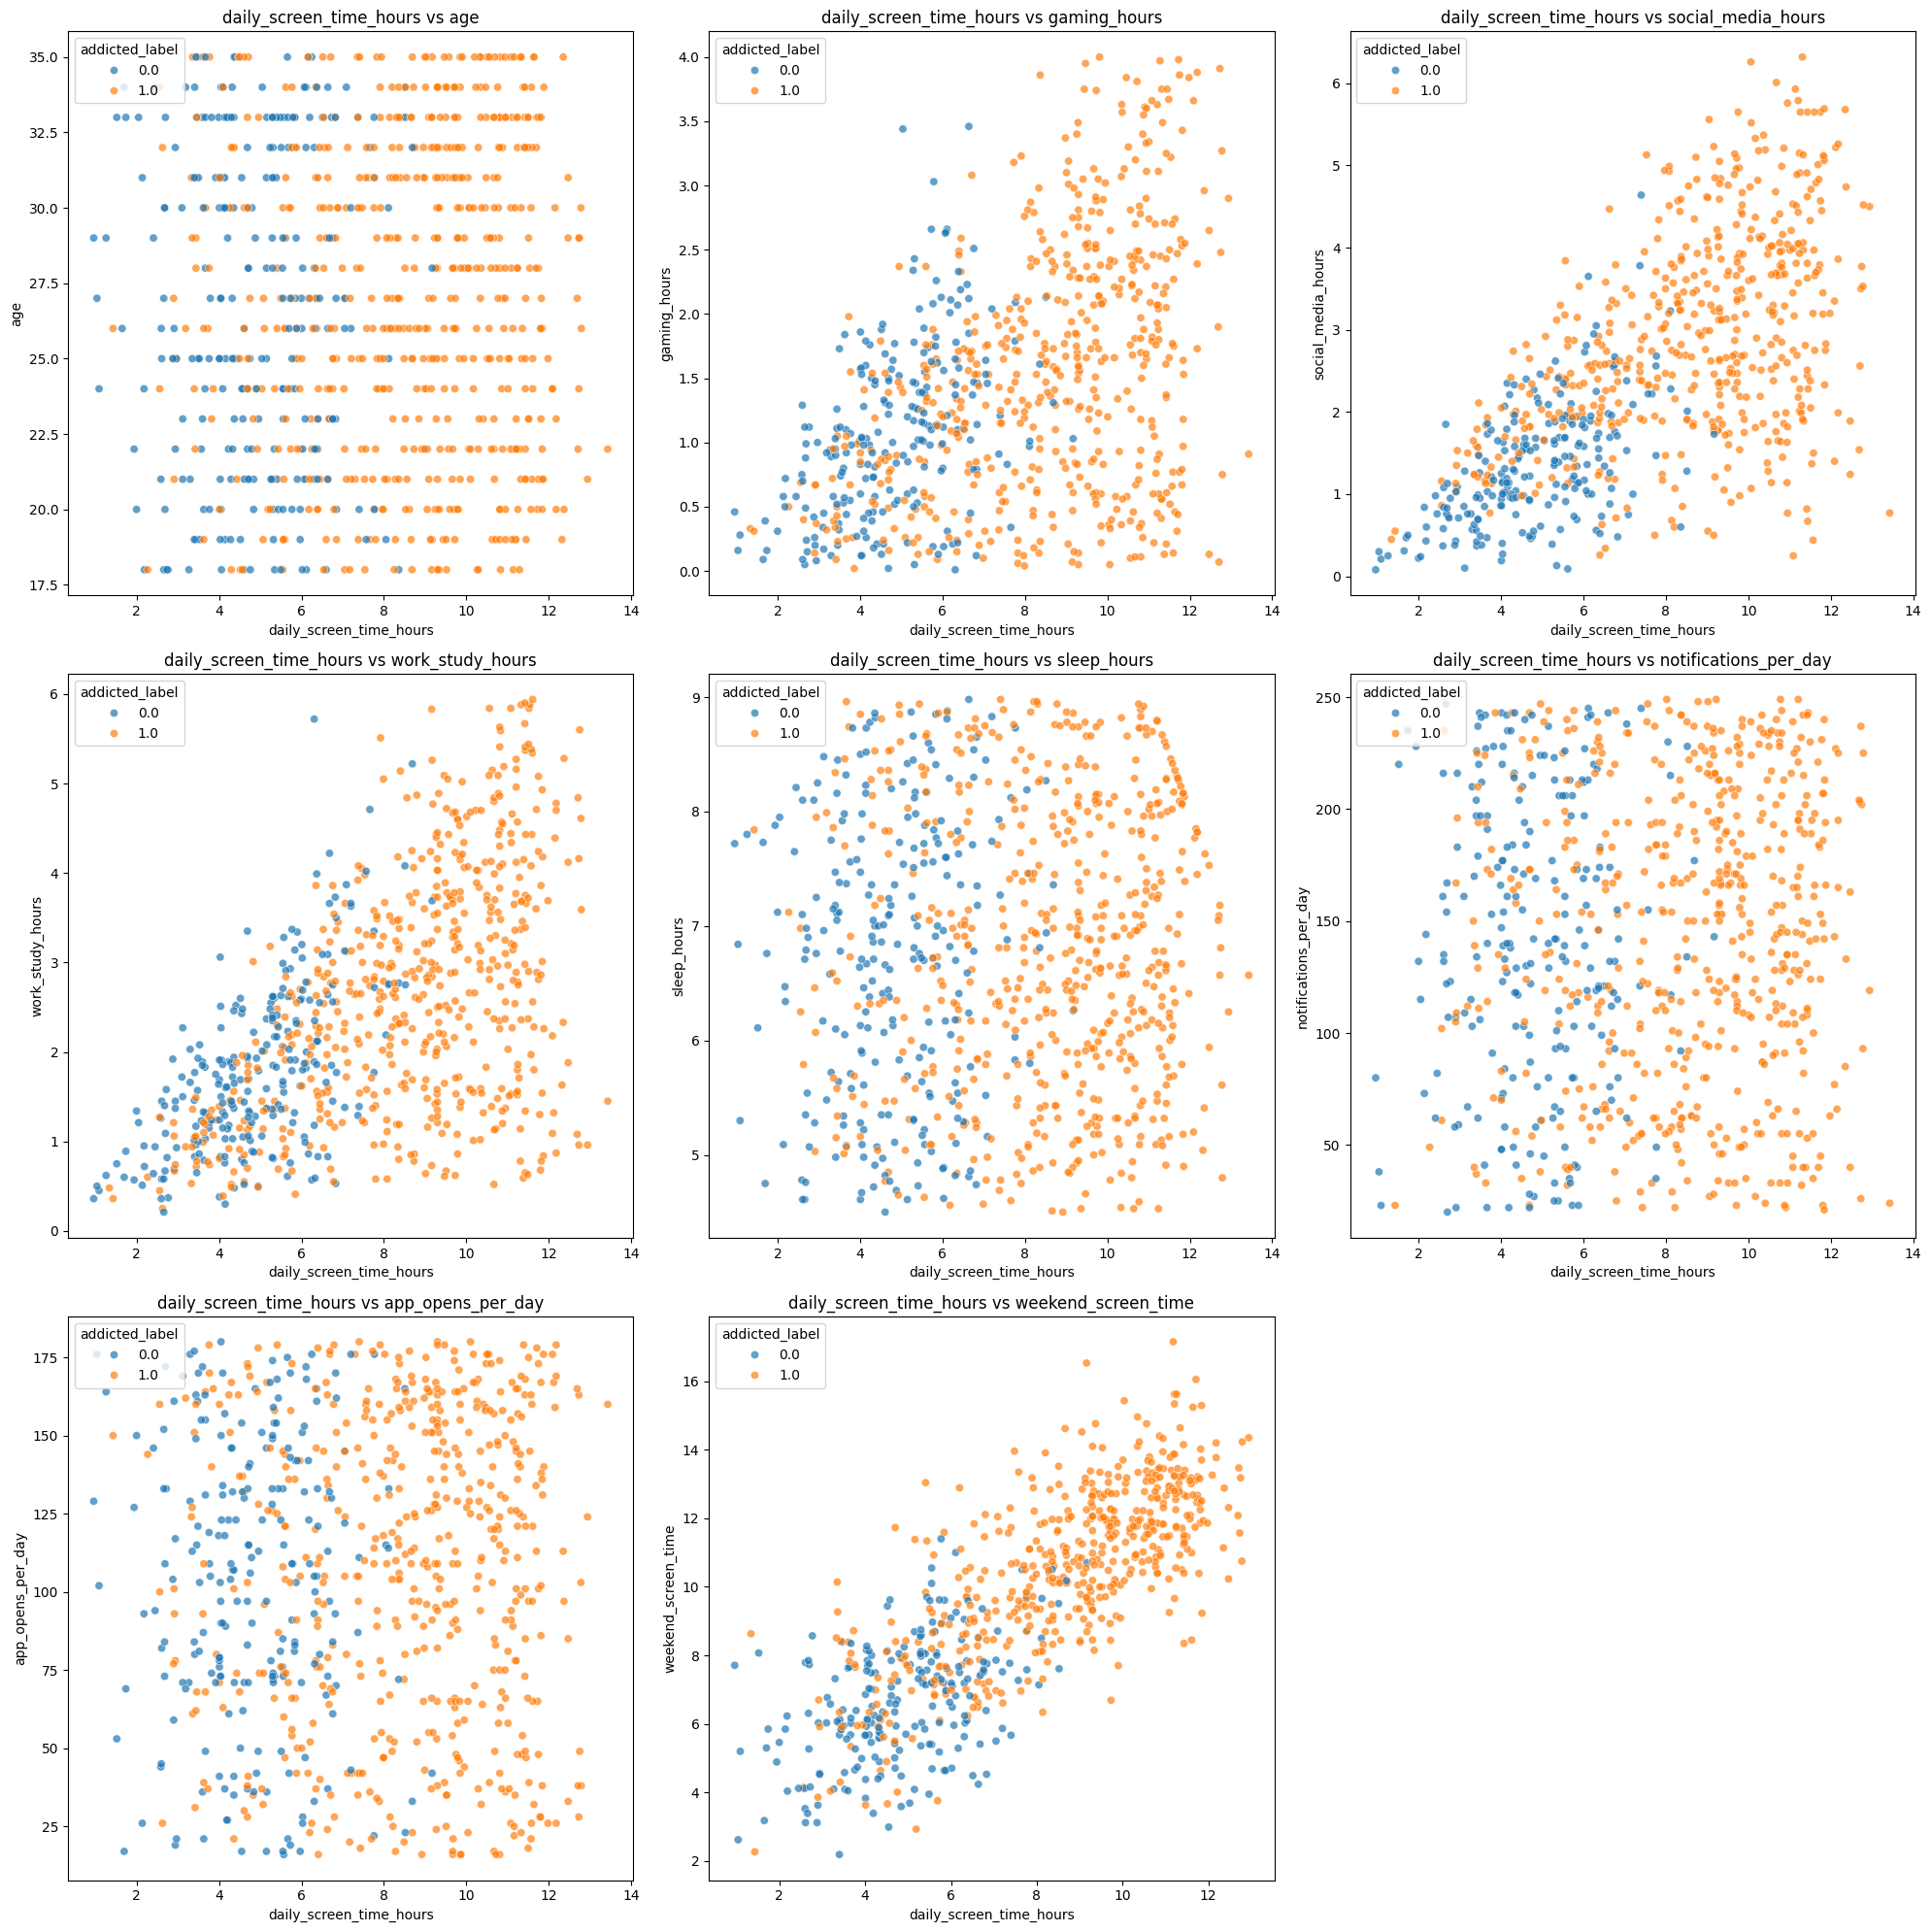

In [ ]:
# code to find connection between the data
# Explicitly define our continuous features based on the dataset
continuous_features = [
    'age',
    'gaming_hours',
    'social_media_hours',
    'work_study_hours',
    'sleep_hours',
    'notifications_per_day',
    'app_opens_per_day',
    'weekend_screen_time'
]

# Create a grid of subplots for all continuous features against gaming_hours
fig, axes = plt.subplots(3, 3, figsize=(20, 20))
axes = axes.flatten()

for i, feature in enumerate(continuous_features):
    sns.scatterplot(
        data=df_new,
        x='daily_screen_time_hours',
        y=feature,
        hue='addicted_label',
        ax=axes[i],
        alpha=0.7
    )
    axes[i].set_title(f'daily_screen_time_hours vs {feature}')

# Hide the remaining unused subplots in our 3x3 grid
for j in range(len(continuous_features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Let us check if there is any correlation between our numerical columns by using the correlation matrix and tell us what features are most correlated to one another.

<Axes: >

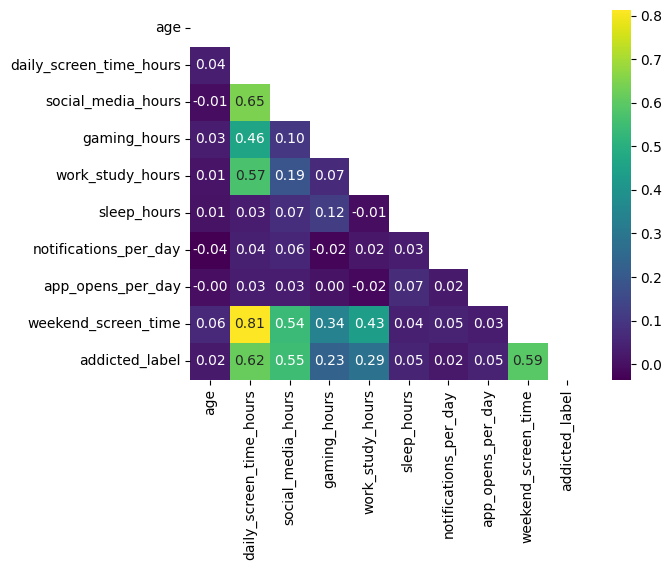

In [ ]:
df_num = df.select_dtypes(include = 'number')

corr = df_num.corr() # correlation matrix

#mask is used to selectively highlight or hide certain data points based on specific conditions
#Since the correlation matrix generally shows correlation between feature in both triangles we use np.triu to avoid duplicate information.
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt=".2f", cmap = 'viridis',mask = mask) # visualising our correlation matrix

How do we intepret this graphs and all this decimal numbers?

Firstly the correlation coefficient is the decimal valuse you see in the square that tell us the relationships between the features. The correlation coefficient generally has a range between -1 to 1.

The Magnitude (Strength):
* 0.7 to 1.0 (-0.7 to -1.0): Strong correlation
* 0.3 to 0.69 (-0.3 to -0.69): Moderate correlation
* 0.1 to 0.29 (-0.1 to -0.29): Weak correlation
* 0.0 to 0.09: No correlation

The Sign (Direction):
* Positive (+): As one variable increases, the other tends to increase.
* Negative (-): As one variable increases, the other tends to decrease (inverse relationship).

Intepreting our results:

Here we can see that daily_screen-time_hours, social_media_hours and weekend_screen_time have a moderate correlation to our addicted label, whcih does mean when it comes to makeing our model this will probably be the more important factors n determing hwther somoene is addicted to their phone or not.

whereas features like gaming_hours and work_study_hours have a weaker correlation meaning they will have some weight in the desicion but not so important as the one above

The rest of the features have no correlation.

NOTE: However sometimes after data tranformation sometimes the correlation coefficients may change, Moreover after we encode our categorical features(columns with categories like gender or maritial stauts) we will be able to check the correlation btween all the features.
 so lets come back to this later.

#Handling Outliers

Outliers are data points that differ significantly from other observations. They may arise due to errors or genuine variations in the data.


* Analyze outliers carefully before taking any action.
* Use domain knowledge to determine whether they are valid or erroneous.
* Using statistical methods such as Interquartile Range (IQR) or Z-score to identify extreme values.
* Remove outliers only when they are clearly incorrect or harmful to analysis.

In [ ]:
#This is a function used to detect outliers in a specified dataset
def detect_outliers_iqr(data, feature):
    Q1 = data[feature].quantile(0.25) # calculates the 25th percentile of selected feature
    Q3 = data[feature].quantile(0.75) # calculates the 75th percentile of selected feature
    IQR = Q3 - Q1 # measures the spread of the middle 50% of your data
    #defines the lower and upper boundary of our data
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    #Here the actual filtering takes place, where all the outliers are added to 'outliers' dataframe
    outliers = data[(data[feature] < lower_bound) | (data[feature] > upper_bound)]
    return outliers

In [ ]:
for feature in df.select_dtypes(include='number'):
    outliers_iqr = detect_outliers_iqr(df, feature)
    print(f"{feature} - IQR Outliers: {len(outliers_iqr)}")

age - IQR Outliers: 0
daily_screen_time_hours - IQR Outliers: 0
social_media_hours - IQR Outliers: 1
gaming_hours - IQR Outliers: 3
work_study_hours - IQR Outliers: 0
sleep_hours - IQR Outliers: 0
notifications_per_day - IQR Outliers: 0
app_opens_per_day - IQR Outliers: 0
weekend_screen_time - IQR Outliers: 0
addicted_label - IQR Outliers: 0


Let's look closely only to the detected outliers

In [ ]:
outliers_social_media_hrs = detect_outliers_iqr(df, 'social_media_hours')
outliers_gaming_hrs = detect_outliers_iqr(df, 'gaming_hours')

display(outliers_social_media_hrs.head())
display(outliers_gaming_hrs.head())

,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
336,35.0,11.31,6.32,0.56,0.78,7.39,144.0,144.0,12.84,Male,High,No,1.0


,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
77,20.0,9.81,NaN,4.00,NaN,5.32,166.0,144.0,NaN,Female,High,No,1.0
207,20.0,11.73,3.79,3.98,NaN,8.27,183.0,65.0,12.46,Other,Medium,Yes,1.0
500,NaN,11.28,1.99,3.97,1.71,7.46,232.0,NaN,NaN,Female,High,Yes,1.0


We can see that these flagged outliers are not anything extreme or impossible values and are actually plausible so let leave them as is as we want our models to learn a wide variety of cases.

Let's now explore the addicted/not addicted values

In [ ]:
df_num = df.select_dtypes(include = 'number')

In [ ]:
#df_num.head()

In [ ]:
# split df into addicted and not addicted numerical variables
addicted_df_num = df_num[df_num['addicted_label'] == 1]
not_addicted_df_num = df_num[df_num['addicted_label'] == 0]

In [ ]:
# find the numerical outliers in the addicted dataset
for feature in addicted_df_num.select_dtypes(include='number'):
    outliers_iqr = detect_outliers_iqr(addicted_df_num, feature)
    print(f"{feature} - IQR Outliers: {len(outliers_iqr)}")

age - IQR Outliers: 0
daily_screen_time_hours - IQR Outliers: 0
social_media_hours - IQR Outliers: 0
gaming_hours - IQR Outliers: 0
work_study_hours - IQR Outliers: 0
sleep_hours - IQR Outliers: 0
notifications_per_day - IQR Outliers: 0
app_opens_per_day - IQR Outliers: 0
weekend_screen_time - IQR Outliers: 7
addicted_label - IQR Outliers: 0


In [ ]:
# numerical outliers for screen time
outliers_weekend_screen_time_addicted = detect_outliers_iqr(addicted_df_num, 'weekend_screen_time')

# Display only the rows in df that have indices matching outliers_weekend_screen_time_addicted
display(df.loc[outliers_weekend_screen_time_addicted.index])

,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
498,18.0,4.52,1.89,0.87,1.46,8.81,231.0,NaN,3.67,Male,High,Yes,1.0
602,26.0,1.43,0.55,0.31,0.36,7.84,23.0,150.0,2.27,Female,High,Yes,1.0
610,20.0,5.19,2.51,NaN,NaN,5.31,136.0,126.0,2.93,Male,Medium,No,1.0
675,30.0,5.69,2.47,0.46,2.17,5.09,40.0,136.0,3.76,Other,Medium,Yes,1.0
798,34.0,NaN,NaN,0.80,NaN,8.53,96.0,89.0,2.13,Other,NaN,Yes,1.0
935,31.0,4.01,2.05,0.85,0.81,8.85,70.0,160.0,3.63,NaN,Medium,No,1.0
968,33.0,NaN,NaN,NaN,1.84,7.47,225.0,29.0,3.34,Other,Low,NaN,1.0




---



In [ ]:
for feature in not_addicted_df_num.select_dtypes(include='number'):
    outliers_iqr = detect_outliers_iqr(not_addicted_df_num, feature)
    print(f"{feature} - IQR Outliers: {len(outliers_iqr)}")

age - IQR Outliers: 0
daily_screen_time_hours - IQR Outliers: 0
social_media_hours - IQR Outliers: 3
gaming_hours - IQR Outliers: 3
work_study_hours - IQR Outliers: 3
sleep_hours - IQR Outliers: 0
notifications_per_day - IQR Outliers: 0
app_opens_per_day - IQR Outliers: 0
weekend_screen_time - IQR Outliers: 2
addicted_label - IQR Outliers: 0


let us take a look at these feature with outliers

In [ ]:
for feature in not_addicted_df_num.select_dtypes(include='number'):
    outliers_iqr = detect_outliers_iqr(not_addicted_df_num, feature)
    if len(outliers_iqr) > 0:
      print(f"{feature}: ")
      outliers_not_addicted = detect_outliers_iqr(not_addicted_df_num, feature)
      display(df.loc[outliers_not_addicted.index])


social_media_hours: 


,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
34,18.0,6.12,3.65,0.31,2.00,8.88,245.0,168.0,9.26,Male,Medium,Yes,0.0
65,20.0,7.40,4.64,1.21,1.39,7.27,245.0,111.0,5.67,NaN,High,No,0.0
392,33.0,7.37,3.78,0.91,1.29,7.93,121.0,87.0,7.77,Other,Low,Yes,0.0


gaming_hours: 


,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
466,33.0,5.79,1.07,3.03,1.21,7.84,41.0,109.0,8.94,Female,Medium,Yes,0.0
857,25.0,5.04,NaN,3.44,1.06,8.26,45.0,151.0,3.69,Male,High,Yes,0.0
900,21.0,6.64,1.26,3.46,0.83,8.98,132.0,73.0,4.24,Other,High,No,0.0


work_study_hours: 


,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
340,32.0,7.66,2.22,0.34,4.71,8.12,NaN,NaN,10.50,Male,Low,No,0.0
378,28.0,6.31,0.56,0.01,5.72,4.82,169.0,93.0,7.19,Other,High,Yes,0.0
934,32.0,8.69,NaN,1.31,5.22,7.36,177.0,33.0,10.18,Other,Medium,Yes,0.0


weekend_screen_time: 


,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
282,27.0,NaN,NaN,NaN,NaN,5.66,182.0,41.0,11.41,Male,High,Yes,0.0
782,20.0,5.77,0.73,0.19,3.37,7.56,80.0,109.0,11.40,Female,High,Yes,0.0


Since None of these outliers seem to be extreme or impossible values there is no need to do anything to our data or to remove them as we want our model to learn this cases as well.

What to do in case we do have outliers?


1. Deletion (Trimming): delete the outliers only when the outlier is a confirmed data error, typo, or irrelevant to the target population, and when dropping it does not severely shrink your sample size.

2. Capping/Imputation: When you want to keep the data point in the dataset, but need to limit the extreme pull it has on your metrics, in does case you either replace the value with a threshold value or you use a model-based imputation(median is a safe option since mean itself gets effected by outliers).


######Z-Scores
What are Z-Scores?

We could use z-score method to weed out the potential outliers. Z-Score in statistics measures how many standard deviations a data point lies away from the mean of a distribution. Commonly used for thta data that assumes bell shaped curve (normaly distributed)

In [ ]:
def detect_outliers_zscore(data, feature, threshold=3): # threshold=3 is the max std. an observation can be away from the mean before being flagged as an outlier.
#threshold = 3 is the default value and can be changed depending on the context of the data.
    check_features = [    ] #features with extreme outliers
    z_scores = np.abs(stats.zscore(data[feature])) #stats.z_score calculates the z-scores for each observation in specified feature
    #np.abs is a numpy function that converts all negative values to psitive integers

    outliers = data[z_scores > threshold] #Filter out the outliers
    return outliers

for feature in check_features:
    outliers_zscore = detect_outliers_zscore(df, feature)
    print(f"{feature} - Z-score Outliers: {len(outliers_zscore)}")

--- Z-score Outliers in Addicted Group (addicted_df_num) ---


AttributeError: 'numpy.ndarray' object has no attribute 'index'

#Handling Missing Data

What are Missing values?

Missing values appear when some entries in a dataset are left blank, marked as NaN, None or special strings like "Unknown". If not handled properly, they can reduce accuracy, create bias and break algorithms that require complete data.

Well handling missing data really depends and differs from case to case, we can either delete the rows containing missing data if the number of null values is relatively low compared to the size of the dataset or drop the columns if it contains too many missing values, we can do this using the **dropna** method in pandas

However if there are too many missing values to the point where the model will train on insufficient data or the data is too valuable to drop we may peroform data **imputation** where we fill in the missing values with **mean, mode and median** depending on the data/value you are imputing.

[Data Imputaion using mean, medain and mode](https://apxml.com/courses/intro-data-cleaning-preprocessing/chapter-2-handling-missing-data/basic-imputation-mean-median-mode)

Imputation can also be done within the sklearn library, where we can impute different missing values with the help of **KNNImputer(K-Nearest Neighbors) which is a part of sklearn.impute**

[Using KNNImputer in Scikit-Learn to Handle Missing Data in Python](https://www.geeksforgeeks.org/machine-learning/python-imputation-using-the-knnimputer/)

In [ ]:
# Method of checking the number of columns with null values
missing_data = df.isna().sum()
print(missing_data[missing_data > 0])

age                         48
daily_screen_time_hours    124
social_media_hours         196
gaming_hours               161
work_study_hours            71
sleep_hours                 49
notifications_per_day       96
app_opens_per_day          115
weekend_screen_time        165
gender                      43
stress_level                79
academic_work_impact        61
dtype: int64


In [ ]:
# To check for percentage of missing data in each column
missing_percentage = round((df.isna().sum()/len(df)) * 100,2)
print(missing_percentage)

age                         4.8
daily_screen_time_hours    12.4
social_media_hours         19.6
gaming_hours               16.1
work_study_hours            7.1
sleep_hours                 4.9
notifications_per_day       9.6
app_opens_per_day          11.5
weekend_screen_time        16.5
gender                      4.3
stress_level                7.9
academic_work_impact        6.1
addicted_label              0.0
dtype: float64


Columns like age, work_study_hours, sleep_hours, notifications_per_day, gender, stress_level, academic_work_impact have less than **10%** missing values, so depending on their importance of the feature and its potential relation to other features we could consider deleting some of these missing values.

Whereas columns like daily_screen_time_hours, social_media_hours, gaming_hours, apps_opens_per_day, weekend_screen_time have about **11%-20%** missing data, imputing them is porbably better

Firstly before doing anything we need to understand what kind of missing data it is i.e. if it is Missing Completely At Random (MCAR), Missing at Random (MAR) or Missing Not At Random (MNAR) and then deal with them accordingly.

Link on how to check and deal with types of [missing data](https://stats.stackexchange.com/questions/462507/how-to-decide-whether-missing-values-are-mar-mcar-or-mnar)

If it is MCAR, which we will test for using the Little MCAR test (if p>0.05 then MCAR True) then we can either delete the data if it is less than 5% missing values or impute the data

Note: p-value (p) is a measure of how well our data are consistent with the hypothesis that there is no effect

[simple explanation of p-value](https://quantifyinghealth.com/p-value-explanation/)

In [ ]:
#pip install pyampute

In [ ]:
df_numeric = df.select_dtypes(include = 'number') #selecting only the numeric columns within the dataset
from pyampute.exploration.mcar_statistical_tests import MCARTest
mt = MCARTest(method='little')
p_value = mt.little_mcar_test(df_numeric)
print(f"\nMCAR test result for missing values: {p_value}")


MCAR test result for missing values: 0.15851902900126824


How to intepret this test?

Basically if the P-value < 0.05 is not MCAR

From the above test we can conclude that since p_value is greater than 0.05 that means our missing data is most likely MCAR type (remember not 100%). So we must deal with the data as if it were MAR

(note if p_value shows 0.0 its just that p-value is very small then rounded to 0.0)

Now for data that has missingness of about 5% it is generally safe to delete the rows but since e are working with a relatively samller dataset we will be imputing the values



###Now time to deal with Missing data in our categorical columns

Firslty for the gender column let us fill the missing values with 'unknown' as we cannot impute/assume someones gender and it could skew any group comparisions

In [ ]:
df_new['gender']=df_new['gender'].fillna("Unknown")

In [ ]:
df_new['gender'].isna().sum()

np.int64(0)

Now while dealing with stress_levels it could prove to be slightly more tricky as it could be an important feature in our project.

Let us check if there is a pattern in our missing data. Now when it comes to determing stress levels some of the most determing factors could be social comparision, distrupted sleeping hours or even pressure from academic life.

In [ ]:
df_new.groupby(df_new['stress_level'].isna())[['sleep_hours','social_media_hours']].describe().T


stress_level                   False      True 
sleep_hours        count  886.000000  65.000000
                   mean     6.761264   6.731077
                   std      1.221518   1.277740
                   min      4.500000   4.530000
                   25%      5.742500   5.630000
                   50%      6.760000   6.620000
                   75%      7.830000   7.750000
                   max      8.980000   8.940000
social_media_hours count  752.000000  52.000000
                   mean     2.444162   2.315577
                   std      1.352578   1.348493
                   min      0.080000   0.220000
                   25%      1.400000   1.162500
                   50%      2.275000   2.380000
                   75%      3.362500   3.265000
                   max      6.320000   5.200000

From the above comparisions we can see that the means of null and non-null valuse are almost the same which means that missingness is most likely to be random and with only 79 missing rows that expected.

Since stress level is an oredered set instead of filling the null values with unknown we will instead use the mode imputation method where we will impute the mode and also create a new missing_indicator as well so that information isn't lost since stress_levels could be an important feature in detremining the addicted_label.

In [ ]:
df_new['stress_level'].unique() #just to make sure there are only three categories and no typos or errors

array(['Medium', 'Low', 'High', nan], dtype=object)

In [ ]:
order = {"Low": 0, "Medium": 1, "High": 2}
df_new["stress_missing"] = df_new["stress_level"].isna() #creating a new column which will show True for null values
df_new["stress_level"] = df_new["stress_level"].map(order) #.map turns the lables into 0,1,2 as mentioned above and leaves NaN as NaN
df_new["stress_level"] = df_new["stress_level"].fillna(df_new["stress_level"].median())
df_new['stress_level'] = df_new['stress_level'].astype(int)

In [ ]:
df_new['stress_level'].isna().sum()

np.int64(0)

In [ ]:
df_new.head()

,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label,stress_missing
0,33.0,7.91,1.89,1.96,3.19,4.75,112.0,179.0,10.25,Other,1,No,1.0,False
1,29.0,12.47,1.24,0.13,4.12,5.94,40.0,85.0,10.23,Male,1,Yes,1.0,False
2,29.0,12.75,3.77,2.48,5.60,6.81,202.0,49.0,13.18,Female,0,Yes,1.0,False
3,32.0,8.96,2.76,2.62,3.02,7.99,226.0,109.0,10.05,Other,2,No,1.0,False
4,33.0,8.43,3.46,2.58,1.63,6.49,84.0,140.0,8.69,Other,0,No,1.0,False


Now dealing with the missing valuse in academic_work_impact columns

this a bit iffy as people may genuienly not know or maybe they maybe be related to something else

In [ ]:
df_new['academic_work_impact'].unique()

array(['No', 'Yes', nan], dtype=object)

In [ ]:
before = df_new["academic_work_impact"].value_counts(normalize=True)
#filled = df["academic_work_impact"].fillna(df["academic_work_impact"].mode()[0])
#after = filled.value_counts(normalize=True)
print(before)
#print(after)

academic_work_impact
No     0.507987
Yes    0.492013
Name: proportion, dtype: float64


In [ ]:
df_new.groupby(df["academic_work_impact"].isna())[["age", "sleep_hours", "work_study_hours"]].mean().T

academic_work_impact,False,True
age,26.819398,25.909091
sleep_hours,6.755273,6.827115
work_study_hours,2.392629,2.321379


In [ ]:
df_new.groupby(df["academic_work_impact"].isna())[["age", "sleep_hours", "work_study_hours"]].std().T

academic_work_impact,False,True
age,5.153096,4.884870
sleep_hours,1.220580,1.305713
work_study_hours,1.298115,1.277652


If the means for sleep_hours and work_study_hours are almost identical and the mean for age are only 1 year apart so it should not have much of a significant impact.

In [ ]:
pd.crosstab(df_new['stress_level'], df_new["academic_work_impact"].isna(), normalize="index")

academic_work_impact,False,True
stress_level,,
0,0.940594,0.059406
1,0.935484,0.064516
2,0.941538,0.058462


This is the flat result we were hoping for what I mean by that is that across all stress levels with a missing academic_work_impact is more or less the same and no stress level is noticebly skipping this question.

Also note that since we imputed the stress_level with a median value, it could slightly blur the result. To avoid that lets also run it against the stress_missing feature that we added.

In [ ]:
pd.crosstab(df_new['stress_missing'], df_new["academic_work_impact"].isna(), normalize="index")

academic_work_impact,False,True
stress_missing,,
False,0.945711,0.054289
True,0.860759,0.139241


Now this is not a flat result, in the cases where stress_levels were missing 13.9% of the values were missing and for the other case it was 5.9% which is a significant difference.

This means that people who skipped stress_levels were noticeably likely skipping the academic_work_impact as well which suggest there either could be a shared reason or just pure coincidence.

Also we should avoid imputing with a value since we saw from above value_counts that imputing with mode would be pretty useless since there is a 50/50 split and imputing might create a gap which came synthetically rather than what actual respondents said

Hence we could label our missing data as MAR i.e. the missing data is not random and could have something to do with other observed variables.(also MNAR cant be ruled out)

Considering all these above points, dropping the missing values and having a complete set of 939 datapoints is our best choice.

In [ ]:
df_new = df_new.dropna(subset=['academic_work_impact'])

In [ ]:
df_new['academic_work_impact'].isna().sum()

np.int64(0)

Now before we proceed to imputing our numerical values let us split our dataset. Now why are we dong this?

Well the main beneift is an honest test score. In this dataset the difference maybe tiny but in real world situations it's a good practice.

Other benfits include:

* The test set remains unseen, since MICE uses relationships between features to impute values, by splitting we would keep that information from leaking across the two sets
* Test scores should reflect realistic use, when model meets new data their missing values must be filled with what we aldready knon not using the new data itself

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

drop_cols = ['sleep_hours', 'notifications_per_day', 'app_opens_per_day'] #dropping these columns as donnot have much correlation with other features or our target vairable i.e addicted_label
df_model = df_new.drop(columns=drop_cols)       # for modelling

#Separate the label from the features
y = df_model['addicted_label']
X = df_model.drop(columns='addicted_label')  #the label never goes into the imputer

#Splitting the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2, #defines the split, i.e. here the test set will have 20% of the orignal data
    stratify=y, #preserves class proportions in imbalanced datasets (ensures thta Y/N split is balance between both sets)
    random_state=42) #random number generator that shuffles data before splitting (42 is simply a popular reference to The Hitchhiker's Guide to the Galaxy)



###MICE(Multiple Imputation by Chained Equations))

Since we are dealing with MAR means the probability of data missing depends directly on other observed variables,in this case MICE excels as unlike KNNImputer it uses relationships between variables to estimate missing values rather than relying solely on the nearest observations.

However it does not automatically mean that MICE is better than KNNIpmuter, since the imputaion method depends heavily on the type of missing data, relationship between variables and imputaion accuracy


Why is it important for this dataset?

For our dataset variables like `daily_screen_time` and `weekend_screen_time` or any other variables might be related to one another. MICE can learn this relationship and estimate the values

For more information on [MICE](https://machinelearningplus.com/machine-learning/mice-imputation/).

NOTE: Only apply this method to feature that have strong correlation with other features (which you could check with the correlation matrix) otherwise it will impute mean values which will create wierd relations later on.

In [ ]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
#define the imputer
imputer = IterativeImputer(random_state=100, max_iter=10)
num_cols = ['age', 'daily_screen_time_hours', 'social_media_hours', 'gaming_hours',
            'work_study_hours', 'weekend_screen_time']
# fit on the training set ONLY, then fill in the training data
train_imputed = imputer.fit_transform(X_train[num_cols])   # array

# apply the already-fitted imputer to the test set (transform only, never fit)
test_imputed = imputer.transform(X_test[num_cols])         # array

# convert back to dataframes, keeping each set's own index
X_train_imp = X_train.copy()
X_test_imp = X_test.copy()
X_train_imp[num_cols] = pd.DataFrame(train_imputed, columns=num_cols, index=X_train.index)
X_test_imp[num_cols] = pd.DataFrame(test_imputed, columns=num_cols, index=X_test.index)

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


You may have noticed the .fit_transfrom and .transfrom while imputing the two sets, what does this mean?

In simple terms .fit_transform learns from the data and fills the missing values based on that knowledge from the train set whereas .transfrom does not learn from the test set it instead fills in the  missing values based on information from the train set

A small example:

Say the training values are [2, 4, 6] and the test values are [8, 10]:

scaler.fit_transform(train)  -> learns mean = 4, std ≈ 1.63, then fills train

scaler.transform(test)  -> reuses mean = 4, std ≈ 1.63 to impute values

In [ ]:
X_train_imp.isna().sum()

,0
age,0
daily_screen_time_hours,0
social_media_hours,0
gaming_hours,0
work_study_hours,0
weekend_screen_time,0
gender,0
stress_level,0
academic_work_impact,0
stress_missing,0


Lets just take a look at our data before moving forward

In [ ]:
X_train_imp.head()

,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,weekend_screen_time,gender,stress_level,academic_work_impact,stress_missing
61,34.000000,11.38,2.810000,0.13,0.59,10.50,Female,0,No,False
707,25.000000,2.94,1.530000,0.37,0.74,5.92,Male,1,No,False
799,34.000000,11.42,2.520654,2.21,5.90,13.25,Male,0,Yes,False
786,27.305684,11.26,5.650000,0.91,2.75,15.62,Male,2,No,False
115,26.000000,6.80,3.320000,1.98,1.16,12.11,Male,0,No,False


Well after imputation, we can see that the count columns like age, notifications_per_day and apps_opens_per_day can contain decimals like 26.8, so  we must convert them to whole numbers.

In [ ]:
X_train_imp[['age']] = X_train_imp[['age']].round().astype(int)
X_test_imp[['age']] = X_test_imp[['age']].round().astype(int)

In [ ]:
X_test_imp.head()

,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,weekend_screen_time,gender,stress_level,academic_work_impact,stress_missing
29,26,8.18,3.570000,0.81,2.99,11.870000,Male,0,Yes,False
899,28,5.15,1.750604,1.20,1.37,7.486539,Unknown,2,Yes,False
42,22,9.57,2.530000,1.26,4.43,12.010000,Female,1,No,False
894,26,5.70,2.100000,0.98,2.03,7.918271,Male,2,Yes,False
191,23,10.41,5.190000,3.13,1.32,11.970000,Female,1,Yes,False


###KNNImputer

KNNImputer to impute the missing values based on its neighbouring values

In [ ]:
from sklearn.impute import KNNImputer

imputer = KNNImputer(n_neighbors=5)
sample_imputed = imputer.fit_transform(df)

sample_imputed_df = pd.DataFrame(
    sample_imputed,
    columns=df.columns,
    index=df.index
)


sample_imputed_df.head()

ValueError: could not convert string to float: 'Other'

In [ ]:
sample_imputed_df.isna().sum()

Because MAR means the probability of data missing depends directly on other observed variables, MICE excels by creating a series of regression models where each feature with missing values is explicitly modeled as a function of the other

#Performing Data Transformation

Why is Data transformation important?

Data transformation is crucial in the our machine learning pipeline as it plays an important role in preparing raw data into meaningful insights and accurate model building.

Raw data, often sourced from diverse channels, may be inconsistent or exhibit variations that could impact the reliability of analyses. Many models perform more effectively when features share similar ranges. Therefore by applying transformations can help bring data closer to this bell-shaped distribution and support more accurate predictions and calculations.

NOTE: One thing to remember is that not every machine learning model is affected by feature scales in the same way.

for example in KNN relies on calculating distances between data points, so features like annual income could dominate the distance calculation if the data isn't scaled.

However for Liner Regression data sclaing is not strictly required but if you train your LR model using gradient descent, unscaled features can cause loss function to become elongated or skewed


In [ ]:
X_train_imp.columns

Index(['age', 'daily_screen_time_hours', 'social_media_hours', 'gaming_hours',
       'work_study_hours', 'weekend_screen_time', 'gender', 'stress_level',
       'academic_work_impact', 'stress_missing'],
      dtype='object')

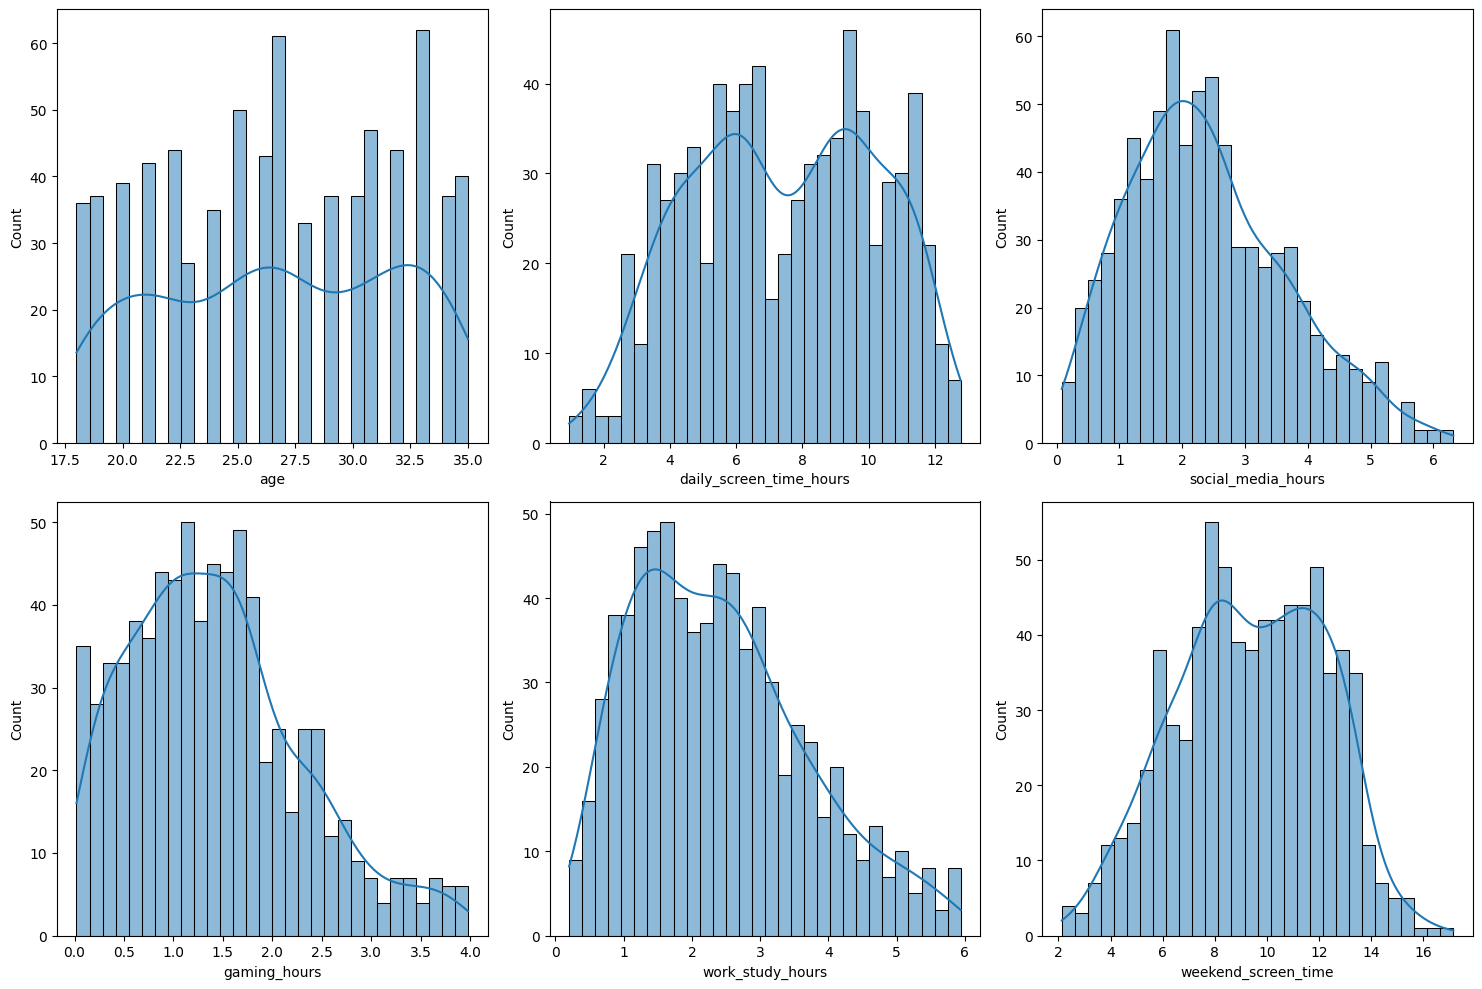

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

continuous_features = [ 'age','daily_screen_time_hours', 'social_media_hours',
       'gaming_hours', 'work_study_hours','weekend_screen_time']

fig, axes = plt.subplots(2, 3, figsize=(15, 10)) #fig represents the entire plot and axes represents each indivisual plotting area

#this loops through each feature and assigns it an index, which ensures all the feauters are plotted
for ax, feature in zip(axes.flat, continuous_features):
    sns.histplot(data=X_train_imp,
                 x=feature,
                 bins=30, #bins determines the number of interval the feature valuse are distributed into
                 kde=True,  #Adds a curve to help visualise the shape of the distribution.
                 ax=ax) #specifes which area the plot should go in, hence why it is indexed in the for loop
    #ax.set_title(feature)
plt.tight_layout() #prevents overlapping between different plots

Well as we can see that the above data is not normally distributed,now scaling our data (i.e.) is not required for basic regression it will not affect the prediction accuracy.

However, if you are using regularized regression models (like Ridge, Lasso, or Elastic Net), scaling your predictor variables is mandatory

##Feature Scaling

Feature scaling normalizes the range of independent variables (features) in a dataset during data preprocessing so no single variable dominates model training

For continous variables feature scaling can be done in two methods:
1. Min-Max normalization
2. Standardisation

###Min-Max normalization
It is a technique where you  change the scale of the feature to 0-1 where the smallest values in ecah feature becomes 0 and largest becomes 1, this is usually used for data that varies widely wihtin its range (not normally distributed).

This technique is particularly useful for models that rely on scale of data like KNN(K-Nearest Neighbours) and Support Vectors Machine(SVM) and it also maintains the original distribution of data.

Note: outliers could heavily affect the scaling process since this method depends on the min and max values of the data

In [ ]:
from sklearn.preprocessing import MinMaxScaler

MinMaxed_df = df_new.copy() # copy the data to a new dataframe 'Transformed_df'

scaler = MinMaxScaler() #Creates an instance for MinMaxScaler()
#default range is set from 0 to 1

#.fit_transform applies the MinMax scaling
MinMaxed_df [continuous_features] = scaler.fit_transform(MinMaxed_df[continuous_features])

print(MinMaxed_df[continuous_features].head(10))

         age  daily_screen_time_hours  social_media_hours  gaming_hours  \
0   0.882353                 0.557338            0.290064      0.488722   
1   0.647059                 0.923015            0.185897      0.030075   
2   0.647059                 0.945469            0.591346      0.619048   
3   0.823529                 0.641540            0.429487      0.654135   
4   0.882353                 0.599038            0.541667      0.644110   
5   0.470588                 0.797915            0.306090      0.902256   
7   1.000000                 0.376905                 NaN      0.433584   
8   0.117647                 0.545309            0.581731      0.190476   
9   0.882353                 0.369687            0.133013      0.343358   
10  0.823529                 0.686447            0.243590      0.666667   

    work_study_hours  weekend_screen_time  
0           0.520906             0.540613  
1           0.682927             0.539281  
2           0.940767             0.735686 

###Standardisation
Also known as z-score normalisation, this technique adjusts the data in such a manner where it's mean becomes 0 and standard deviation becomes 1.
It is particularly useful for models like linear or logistic regression.

Just as in MinMaxScaling it does not mess with the orginal distribution of data.

In [ ]:
from sklearn.preprocessing import StandardScaler
standardised_df = df_new.copy()  # copy the data to a new dataframe 'standardised_df'

scaler = StandardScaler() #Creates an instance fro StandardScaler()

#.fit_transform applies the Satndardistion
standardised_df[continuous_features] = scaler.fit_transform(standardised_df[continuous_features])

print(standardised_df[continuous_features].head(10))


         age  daily_screen_time_hours  social_media_hours  gaming_hours  \
0   1.200065                 0.139518           -0.407141      0.579452   
1   0.423400                 1.766259           -0.889808     -1.404867   
2   0.423400                 1.866147            0.988882      1.143302   
3   1.005899                 0.514096            0.238891      1.295108   
4   1.200065                 0.325023            0.758687      1.251735   
5  -0.159100                 1.209742           -0.332884      2.368592   
7   1.588398                -0.663151                 NaN      0.340900   
8  -1.324098                 0.086007            0.944328     -0.710898   
9   1.200065                -0.695257           -1.134855     -0.049458   
10  1.005899                 0.713872           -0.622485      1.349324   

    work_study_hours  weekend_screen_time  
0           0.614606             0.297796  
1           1.331441             0.290786  
2           2.472211             1.324716 

what does this mean for our data?

Well since we are going to create a logisitc regression model standardisation would be the better choice. You may not see it affect to much here as the values are relatively small but for other datasets like maybe house pricing some values maybe be in the 10,000s the model may tend to favour those larger values more.

In [ ]:
#add code here (apply on both train and test sets)
X_train_sc = X_train_imp.copy()
X_test_sc  = X_test_imp.copy()



#Also ensure to use .fit_tranfrom for train and .tranfrom for test (same logic applies here)


X_train_sc.head()

Answer

In [ ]:
# @title
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_sc = X_train_imp.copy()
X_test_sc  = X_test_imp.copy()

X_train_sc[num_cols] = scaler.fit_transform(X_train_imp[num_cols])   # learns mean/std, then scales train
X_test_sc[num_cols]  = scaler.transform(X_test_imp[num_cols])        # reuses train's mean/std



## Encoding Categorical Data

Now that we have transformed our numerical data into something the Machine learning models can actually use its time to do the same for our categorical columns.

Since the ML models cant really make sense or intepret the text values on its own, we need to tranfrom it in such a way that it can recognise and understand the distinctions between categories, ensuring it interprets it accurately, we can do this by **Encoding** the categorical data

As we can see from above that 'gender',	'stress_level',	'academic_work_impact' are all categorical features. So now that we know the columns to be encoded it's time to apply this.

Since we aldready encoded the stress_level column into 0,1,2 we only need to focus on the other two.

For academic_work_impact we shall binary encode it since it is a Yes/No question and as a rseult it will change it to 0/1

In [ ]:
for d in (X_train_sc, X_test_sc):
    d['academic_work_impact'] = d['academic_work_impact'].map({'No': 0, 'Yes': 1})

In [ ]:
X_train_sc.head()

,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,weekend_screen_time,gender,stress_level,academic_work_impact,stress_missing
61,1.402737,1.413402,0.334131,-1.470043,-1.425710,0.392005,Female,0,0,False
707,-0.352697,-1.622293,-0.685306,-1.196622,-1.307840,-1.225348,Male,1,0,False
799,1.402737,1.427790,0.103686,0.899605,2.746891,1.363123,Male,0,1,False
786,0.037399,1.370241,2.596007,-0.581425,0.271620,2.200050,Male,2,0,False
115,-0.157649,-0.233930,0.740313,0.637577,-0.977803,0.960550,Male,0,0,False


In [ ]:
X_test_sc.head()

,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,weekend_screen_time,gender,stress_level,academic_work_impact,stress_missing
29,-0.157649,0.262428,0.939422,-0.695350,0.460212,0.875798,Male,0,1,False
899,0.232448,-0.827401,-0.509610,-0.251041,-0.812785,-0.672150,Unknown,2,1,False
42,-0.937842,0.762382,0.111129,-0.182686,1.591765,0.925237,Female,1,0,False
894,-0.157649,-0.629578,-0.231338,-0.501677,-0.294157,-0.519691,Male,2,1,False
191,-0.742794,1.064513,2.229647,1.947719,-0.852075,0.911111,Female,1,1,False


###One-Hot Encoding
One-Hot Encoding is typically used for nominal data. This method avoids imposing any order by creating separate binary columns for each category within a variable. With One-Hot Encoding, each category becomes its own entity, allowing the model to treat them independently.

Since the gender column is an unordered dataset we will apply this method on this column

In [ ]:
X_train_sc['gender'].value_counts()

,count
gender,
Male,252
Female,245
Other,226
Unknown,28


In [ ]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False, drop=None)

encoded_data_train=encoder.fit_transform(X_train_sc[['gender']])
encoded_data_test=encoder.transform(X_test_sc[['gender']])

cols = encoder.get_feature_names_out(['gender'])
train_enc_df = pd.DataFrame(encoded_data_train, columns=cols, index=X_train_sc.index)
test_enc_df  = pd.DataFrame(encoded_data_test,  columns=cols, index=X_test_sc.index)

X_train_enc = pd.concat([X_train_sc.drop(columns='gender'), train_enc_df], axis=1)
X_test_enc  = pd.concat([X_test_sc.drop(columns='gender'),  test_enc_df],  axis=1)


In [ ]:
X_train_enc.head()

,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,weekend_screen_time,stress_level,academic_work_impact,stress_missing,gender_Female,gender_Male,gender_Other,gender_Unknown
61,1.402737,1.413402,0.334131,-1.470043,-1.425710,0.392005,0,0,False,1.0,0.0,0.0,0.0
707,-0.352697,-1.622293,-0.685306,-1.196622,-1.307840,-1.225348,1,0,False,0.0,1.0,0.0,0.0
799,1.402737,1.427790,0.103686,0.899605,2.746891,1.363123,0,1,False,0.0,1.0,0.0,0.0
786,0.037399,1.370241,2.596007,-0.581425,0.271620,2.200050,2,0,False,0.0,1.0,0.0,0.0
115,-0.157649,-0.233930,0.740313,0.637577,-0.977803,0.960550,0,0,False,0.0,1.0,0.0,0.0


In [ ]:
X_test_enc.head()

,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,weekend_screen_time,stress_level,academic_work_impact,stress_missing,gender_Female,gender_Male,gender_Other,gender_Unknown
29,-0.157649,0.262428,0.939422,-0.695350,0.460212,0.875798,0,1,False,0.0,1.0,0.0,0.0
899,0.232448,-0.827401,-0.509610,-0.251041,-0.812785,-0.672150,2,1,False,0.0,0.0,0.0,1.0
42,-0.937842,0.762382,0.111129,-0.182686,1.591765,0.925237,1,0,False,1.0,0.0,0.0,0.0
894,-0.157649,-0.629578,-0.231338,-0.501677,-0.294157,-0.519691,2,1,False,0.0,1.0,0.0,0.0
191,-0.742794,1.064513,2.229647,1.947719,-0.852075,0.911111,1,1,False,1.0,0.0,0.0,0.0


If you were to have a column/features which have ordered categories like Low, Medium, and High. Using Label Encoding, we can assign Low as 0, Medium as 1, and High as 2, preserving their natural order.

However the columns must have no missing values and since we aldready dealt with this while imputing our data earlier we dont need to do it again


###Example of using Label Encoding on an Ordered Category like stress_level

In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
# this will be applied to the 'Risk_Level' column:
label_encoder.fit(X_train_encoded["stress_level"])
# Natural order should be as follows (note that the automated, alphabetic ranking [High, Low, Medium] is not our goal)
label_encoder.classes_ = np.array(["Low", "Medium", "High"])
# apply the encoder to the data"
X_train_encoded["stress_level"] = label_encoder.transform(X_train_encoded["stress_level"])

print("Data with encoded 'Risk_Level':")
print(X_train_encoded['stress_level'].head())

,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,weekend_screen_time,stress_level,stress_missing,gender_Female,gender_Male,gender_Other,gender_Unknown
61,1.402737,1.413402,0.334131,-1.470043,-1.425710,0.392005,0,False,1.0,0.0,0.0,0.0
707,-0.352697,-1.622293,-0.685306,-1.196622,-1.307840,-1.225348,1,False,0.0,1.0,0.0,0.0
799,1.402737,1.427790,0.103686,0.899605,2.746891,1.363123,0,False,0.0,1.0,0.0,0.0
786,0.037399,1.370241,2.596007,-0.581425,0.271620,2.200050,2,False,0.0,1.0,0.0,0.0
115,-0.157649,-0.233930,0.740313,0.637577,-0.977803,0.960550,0,False,0.0,1.0,0.0,0.0


In [ ]:
X_train_enc.head()

,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,weekend_screen_time,stress_level,academic_work_impact,stress_missing,gender_Female,gender_Male,gender_Other,gender_Unknown
61,1.402737,1.413402,0.334131,-1.470043,-1.425710,0.392005,0,No,False,1.0,0.0,0.0,0.0
707,-0.352697,-1.622293,-0.685306,-1.196622,-1.307840,-1.225348,1,No,False,0.0,1.0,0.0,0.0
799,1.402737,1.427790,0.103686,0.899605,2.746891,1.363123,0,Yes,False,0.0,1.0,0.0,0.0
786,0.037399,1.370241,2.596007,-0.581425,0.271620,2.200050,2,No,False,0.0,1.0,0.0,0.0
115,-0.157649,-0.233930,0.740313,0.637577,-0.977803,0.960550,0,No,False,0.0,1.0,0.0,0.0


In [ ]:
X_train_enc.to_csv("Smartphone_Addiction_encoded.csv")
X_test_enc.to_csv("Test_set.csv")

#Creating and testing the models

Finally we are going to create out Logisitc regression model.

How does logistic regression model even prdict the outcomes?

Well basically LoR model basically makes this prediction in three steps:
1. first its add weighted_scores to each feature, which means that is looks at each indivisual datapoint and works out (mathematically) how much each feature pushes towards the user being addicted or not.

2. Since that score could be anywhere between -infinity to +infintiy, it then turns it into a probability and makes the ranges from 0 -> 1

3. If the probability is at least 0.5, the model predicts 1 (addicted) otherwise 0. (The 0.5 is just a default, and you can change it)

In [ ]:
from sklearn.linear_model import LogisticRegression

# make sure everything is numeric eg:(stress_missing is True/False) and labels are 0/1 integers
X_train = X_train_enc.astype(float)
X_test  = X_test_enc.astype(float)
y_train = y_train.astype(int)
y_test  = y_test.astype(int)

# create and fit the model on the training set only
#,class_weight='balanced'
model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)

# predict on the test set
y_pred = model.predict(X_test)              # class: 0 or 1
y_prob = model.predict_proba(X_test)[:, 1]  # probability of being addicted

Lets us check how the model actually performs

In [ ]:
print(len(y_test))
y_test.value_counts()

188


,count
addicted_label,
1,132
0,56


In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, roc_auc_score,recall_score)

print(f"Accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred):.3f}")
print(f"Recall   : {recall_score(y_test, y_pred):.3f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob):.3f}")

Accuracy : 0.824
Precision: 0.841
Recall   : 0.924
ROC-AUC  : 0.898


Here is what each of these scores means for your model.
The test set has 188 people: 132 addicted and 56 not addicted.

1. Accuracy(0.824)	: 155 of 188 people classified correctly (33 + 122).

2. Precision(0.841) : 	When the model says "addicted", it's right 84% of the
time (122 of 145).

3. Recall(0.924) :	Of the people who really are addicted, the model finds 92% (122 of 132).

4. ROC-AUC(0.898) :	If you pick one addicted and one non-addicted person at random, there's about a 90% chance the model gives the addicted person the higher probability.



Here is what this means for our data

 About 70% of your test people are addicted, so a model would be expected to be 0.70, but since ours is at 0.82 it is a little bit of an improvement :)

 The model is better at catching addicted people than non-addicted ones. It misses only 10 addicted people, but it wrongly labels 23 of the 56 non-addicted people as addicted.
 The reason is that 70% of the training data is addicted, so the model leans towards predicting "addicted".(nothing much we can do about this)

 ROC-AUC is the most trustworthy single number here, A value near 0.9 means the model ranks people well, and around 0.5 would mean guessing.

You can try adding **class_weight='balanced'** attribute to your model and see it improves. Essentially class_weight ensure that the most equal spread between addicted and not addicted people

In [ ]:
#add your code here